// Copyright (c) 2022 Robert Bosch GmbH

// SPDX-License-Identifier: AGPL-3.0

# ML inference script 

This script uses mmdetection framework to predict on augmented images


The main execution blocks is towards the end of the notebook. The previous cells contain declarations used for the main execution block. 


### The first cell are some test functions in *mmdetection* and *torch*


In [ ]:
from mmdet3d.apis import MonoDet3DInferencer
from mmdet.apis import DetInferencer
import torch



print(torch.cuda.is_available())
print(torch.cuda.current_device())
print(torch.cuda.device(0))
print(torch.cuda.get_device_name(0))



models = MonoDet3DInferencer.list_models('mmdet3d')
#print(models)
# Load the ML model
inferencer = DetInferencer('rtmdet_tiny_8xb32-300e_coco', device="cuda:0")

# Inference on example images from nuScenes
output = inferencer(['n015-2018-11-21-19-38-26+0800__CAM_FRONT__1542801007412469.jpg',
                     'n015-2018-11-21-19-38-26+0800__CAM_FRONT__1542800861912460.jpg'])

#print(output)
#print(len(output['predictions'][0]['scores']))
#print(len(output['predictions'][0]['bboxes']))
#print(len(output['predictions'][0]['labels']))

## Modification to mmdetection class

The following class below has been defined to specifically deal with nuScenes images. The original *MonoDet3DInferencer* is only is intended for KITTI dataset, meanwhile the below class function is intended for nuScenes camera definitions.

In [1]:
# ==============================================================================
#  ORIGINAL COPYRIGHT & PATENT NOTICES 
# ==============================================================================
# Copyright (c) OpenMMLab. All rights reserved.
# Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at
#
#     http://www.apache.org/licenses/LICENSE-2.0
#
# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.
# ==============================================================================

# ==============================================================================
#  MODIFICATION & DERIVATIVE WORK NOTICE
# ==============================================================================
# This file contains modifications made by [Christopher Meszaros/Robert Bosch GmbH] in 2026.
# Copyright (c) 2026 [Christopher Meszaros/Robert Bosch GmbH]. All rights reserved.
#
# These modifications are licensed to the public under the GNU Affero General 
# Public License v3.0 (AGPL-3.0) as part of the combined causal-occlusion-validation project.
# ==============================================================================




import mmengine
import numpy as np
from mmdet3d.apis.inferencers.base_3d_inferencer import InputsType, track
from mmdet3d.apis.inferencers.mono_det3d_inferencer import MonoDet3DInferencer
from mmdet3d.registry import INFERENCERS
from mmengine.config import Config
from mmengine.config.utils import MODULE2PACKAGE
from mmengine.fileio import get_file_backend, isdir, join_path, list_dir_or_file
import os.path as osp
from typing import Optional, Tuple, Union


@INFERENCERS.register_module(name="det3d-mono", force=True)
class FCOS3DInferencer(MonoDet3DInferencer):

    def __call__(
        self, inputs: InputsType, batch_size: int = 1, return_datasamples: bool = False, **kwargs
    ) -> Optional[dict]:
        """Call the inferencer.

        Args:
            inputs (InputsType): Inputs for the inferencer.
            batch_size (int): Batch size. Defaults to 1.
            return_datasamples (bool): Whether to return results as
                :obj:`BaseDataElement`. Defaults to False.
            **kwargs: Key words arguments passed to :meth:`preprocess`,
                :meth:`forward`, :meth:`visualize` and :meth:`postprocess`.
                Each key in kwargs should be in the corresponding set of
                ``preprocess_kwargs``, ``forward_kwargs``, ``visualize_kwargs``
                and ``postprocess_kwargs``.


        Returns:
            dict: Inference results
        """

        (
            preprocess_kwargs,
            forward_kwargs,
            visualize_kwargs,
            postprocess_kwargs,
        ) = self._dispatch_kwargs(**kwargs)

        if "cam_type" in preprocess_kwargs:
            cam_type = preprocess_kwargs.pop("cam_type")
        else:
            cam_type = visualize_kwargs["cam_type_dir"]
        ori_inputs = self._inputs_to_list(inputs, cam_type=cam_type)
        inputs = self.preprocess(ori_inputs, batch_size=batch_size, **preprocess_kwargs)

        results_dict = {"predictions": [], "visualization": []}
        self.show_progress=False
        #print(inputs)
        #print("show progress is: {}".format(self.show_progress))
        for data in track(inputs, description="Inferencezzz") if self.show_progress else inputs:
            preds = self.forward(data, **forward_kwargs)
            #print("length of predictions is {}".format(len(preds)))
            #print("preds is type of {}".format(type(preds)))
            visualization = self.visualize(ori_inputs, preds, **visualize_kwargs)

            results = self.postprocess(preds, visualization, return_datasamples, **postprocess_kwargs)
            #print("length of results is {}".format(len(results['predictions'])))
            #print(type(results))
            #print(results)
            results_dict['predictions'].extend(results['predictions']) # dont comment out this line, since these are the predictions for each batch
            if results["visualization"] is not None:
                results_dict["visualization"].extend(results["visualization"])
        return results_dict

    def _inputs_to_list(self, inputs: Union[dict, list], cam_type="CAM2", **kwargs) -> list:
        """Preprocess the inputs to a list.

        Preprocess inputs to a list according to its type:

        - list or tuple: return inputs
        - dict: the value with key 'img' is
            - Directory path: return all files in the directory
            - other cases: return a list containing the string. The string
              could be a path to file, a url or other types of string according
              to the task.

        Args:
            inputs (Union[dict, list]): Inputs for the inferencer.

        Returns:
            list: List of input for the :meth:`preprocess`.
        """
        if isinstance(inputs, dict):
            #print(inputs)
            assert "infos" in inputs
            infos = inputs.pop("infos")

            if isinstance(inputs["img"], str):
                img = inputs["img"]
                backend = get_file_backend(img)
                if hasattr(backend, "isdir") and isdir(img):
                    # Backends like HttpsBackend do not implement `isdir`, so
                    # only those backends that implement `isdir` could accept
                    # the inputs as a directory
                    filename_list = list_dir_or_file(img, list_dir=False)
                    inputs = [{"img": join_path(img, filename)} for filename in filename_list]

            if not isinstance(inputs, (list, tuple)):
                inputs = [{"img": img_path} for img_path in inputs["img"]]
            #print(inputs)
            # get cam2img, lidar2cam and lidar2img from infos
            info_list = infos["data_list"]
            assert len(info_list) == len(inputs)
            for index, input in enumerate(inputs):
                data_info = info_list[index]
                #print(cam_type)
                #print(data_info)
                #print(data_info["images"][cam_type])
                #print(data_info["images"][cam_type]["img_path"])
                img_path = data_info["images"][cam_type]["img_path"]
                if isinstance(input["img"], str) and osp.basename(img_path) != osp.basename(input["img"]):
                    raise ValueError(f"the info file of {img_path} is not provided.")
                cam2img = np.asarray(data_info["images"][cam_type]["cam2img"], dtype=np.float32)
                lidar2cam = np.asarray(data_info["images"][cam_type]["lidar2cam"], dtype=np.float32)
                if "lidar2img" in data_info["images"][cam_type]:
                    lidar2img = np.asarray(data_info["images"][cam_type]["lidar2img"], dtype=np.float32)
                else:
                    assert cam2img.shape == (3, 3)
                    cam2img_ = np.eye(4)
                    cam2img_[:3, :3] = cam2img
                    lidar2img = cam2img_ @ lidar2cam

                input["cam2img"] = cam2img
                input["lidar2cam"] = lidar2cam
                input["lidar2img"] = lidar2img
            #print(inputs)
        elif isinstance(inputs, (list, tuple)):
            # get cam2img, lidar2cam and lidar2img from infos
            for input in inputs:
                assert "infos" in input
                infos = input.pop("infos")
                info_list = mmengine.load(infos)["data_list"]
                assert len(info_list) == 1, "Only support single sample info" "in `.pkl`, when inputs is a list."
                data_info = info_list[0]
                img_path = data_info["images"][cam_type]["img_path"]
                if isinstance(input["img"], str) and osp.basename(img_path) != osp.basename(input["img"]):
                    raise ValueError(f"the info file of {img_path} is not provided.")
                cam2img = np.asarray(data_info["images"][cam_type]["cam2img"], dtype=np.float32)
                lidar2cam = np.asarray(data_info["images"][cam_type]["lidar2cam"], dtype=np.float32)
                if "lidar2img" in data_info["images"][cam_type]:
                    lidar2img = np.asarray(data_info["images"][cam_type]["lidar2img"], dtype=np.float32)
                else:
                    lidar2img = cam2img @ lidar2cam
                input["cam2img"] = cam2img
                input["lidar2cam"] = lidar2cam
                input["lidar2img"] = lidar2img

        return list(inputs)

    def _load_model_from_metafile(self, model: str) -> Tuple[Config, str]:
        """Load config and weights from metafile.

        Args:
            model (str): model name defined in metafile.

        Returns:
            Tuple[Config, str]: Loaded Config and weights path defined in
            metafile.
        """
        model = model.lower()

        assert self.scope is not None, "scope should be initialized if you want " "to load config from metafile."
        assert self.scope in MODULE2PACKAGE, f"{self.scope} not in {MODULE2PACKAGE}!," "please pass a valid scope."
        #print(self.scope)
        repo_or_mim_dir = FCOS3DInferencer._get_repo_or_mim_dir(self.scope)
        for model_cfg in FCOS3DInferencer._get_models_from_metafile(repo_or_mim_dir):
            model_name = model_cfg["Name"].lower()
            model_aliases = model_cfg.get("Alias", [])
            if isinstance(model_aliases, str):
                model_aliases = [model_aliases.lower()]
            else:
                model_aliases = [alias.lower() for alias in model_aliases]
            if model_name in model or model in model_aliases:
                cfg = Config.fromfile(osp.join(repo_or_mim_dir, model_cfg["Config"]))
                weights = model_cfg["Weights"]
                weights = weights[0] if isinstance(weights, list) else weights
                return cfg, weights
        raise ValueError(f"Cannot find model: {model} in {self.scope}")

# Pre-process info file to match with monocular mmdet3D


Since the mmdet3D framework was designed for kitti dataset, the info file also needs to be updated to match the previous class definition we defined in previous cell. Therefore, the following cells updates the info file, specifically the dictionary . A random numpy array is hardcoded for the lid2seg, since these will not be used in our defined mmdet3D.

- Follow format 

    - info_list = mmengine.load(infos)['data_list']

    - data_info['images'][cam_type]['cam2img'], dtype=np.float32)
"camtype" will be passed as parameter to the FCOS class. This will be hardcoded as the string "nuScenes"


use the *data_set* variable to choose which type of data to create

- **10k_random_fully_visible:** this dataset is used for the augmentations. Due to time restriction, it restricted to only 10k samples of fully visible pedestrians
- **Fully visible:** This data set is used for associational analysis
- **Half_visible:** This data set is used for associational analysis





In [ ]:
#print(infos["data_list"])
import pandas as pd
import pickle
import numpy as np
import os


###################    reformat DF and extract 10k samples for each visibility #####################################
df = pd.read_csv('Pedestrians_annotations_filtered_FOV_with_rain_3D_bbox_eulerian_angels.csv', sep=",")
df['2D_bbox_x1'] = df['2D_bbox_x1'].replace(',', '.', regex=True).astype(float)
df['2D_bbox_y1'] = df['2D_bbox_y1'].replace(',', '.', regex=True).astype(float)
df['2D_bbox_x2'] = df['2D_bbox_x2'].replace(',', '.', regex=True).astype(float)
df['2D_bbox_y2'] = df['2D_bbox_y2'].replace(',', '.', regex=True).astype(float)
df['obj_distance'] = df['obj_distance'].replace(',', '.', regex=True).astype(float)
df['blurr_laplician_variance'] = df['blurr_laplician_variance'].replace(',', '.', regex=True).astype(float)
df['average_brightness_pixel_lvl'] = df['average_brightness_pixel_lvl'].replace(',', '.', regex=True).astype(float)



file_path_nuscenes="path"
###################  creating info files used for mmdetection framework #####################################

def create_info_file(data_set,df_mod):
    print("begin to process the info file")
    #################   process the infos file    ############################################
    infos = pickle.load( open( file_path_nuscenes + "/nuscenes_infos_train.pkl", "rb" ) )
    infos_update_dic = {}
    data_list = []
    with open("infos_" + data_set + ".pkl", 'wb') as fp:
        for row_index,row in df_mod.iterrows():
            if row_index % 1000 == 0:
                print(row_index)
            camera = row.to_dict()["camera"]
            img_path = row.to_dict()["img_path"].split('/')[-1]
            #print(img_path)

            for i,info in enumerate(infos["infos"]):
                if info["cams"][camera]["data_path"].split('/')[-1] == img_path:
                    cam2img = np.asarray(info["cams"][camera]["cam_intrinsic"], dtype=np.float32)
                    lidar2img = np.asarray([[0.9999702572822571, 0.003407371463254094, 0.0069207423366606236, 0.01687305048108101],
                                 [0.006852706428617239, 0.019589632749557495, -0.9997846484184265, -0.32902389764785767],
                                 [-0.0035422123037278652, 0.99980229139328, 0.019565701484680176, -0.4292221665382385],
                                 [0.0, 0.0, 0.0, 1.0]], dtype=np.float32)
                    break
            data_list.append({"images": {"nuScenes":{"cam2img": cam2img, "img_path": img_path, "lidar2cam":lidar2img}} })
        infos_update_dic = {"data_list" : data_list}
        pickle.dump(infos_update_dic, fp)




data_sets = ("10k_random_fully_visible", "Fully_visible", "Half_visible")
for data_set in data_sets:
    # Fully visible - 10k random samples used for the augmentations
    if data_set == "10k_random_fully_visible":
        df_mod = df[df["visibility"] == 4].copy()
        df_mod = df_mod[(df_mod["visibility"] == 4) & (df_mod["obj_distance"] < 40)].copy()  # NuScenes evaluation metrics only consider pedestrians within 40 meters
        df_mod = df_mod.sample(n=10000, ignore_index=True)
        df_mod.to_csv("10k_Fully_Visible_pedestrians.csv")
        create_info_file(data_set, df_mod)

    # Fully visible - used for associational
    elif data_set == "Fully_visible":
        df_mod = df[df["visibility"] == 4].copy()
        df_mod = df_mod[(df_mod["visibility"] == 4) & (df_mod["obj_distance"] < 40)].copy()  # NuScenes evaluation metrics only consider pedestrians within 40 meters
        df_mod.to_csv("FULL-data_fully_visible_pedestrians.csv")
        create_info_file(data_set, df_mod)

    # Half-visible - used for associational analysis
    elif data_set == "Half_visible":
        df_mod = df[df["visibility"] == 2].copy()
        df_mod = df_mod[(df_mod["visibility"] == 2) & (df_mod["obj_distance"] < 40)].copy()   # NuScenes evaluation metrics only consider pedestrians within 40 meters
        df_mod.to_csv("FULL_half_occluded_pedestrians.csv")
        create_info_file(data_set, df_mod)


## ML prediction loops

The following cells define the prediction loops. The function includes an additional step for human augmentation where the synthetic is matched.

- Note, predicting on single image for each annotation. 
    - Since it is harder to debug predicing on a image
    - Another reason
    
    
- For human augmentations there are 4 cases
    - Case 1: detect both synthetic and real pedestrian
    - Case 2: detect real pedestrian
    - Case 3: detect synthetic pedestrian
    - Case 4: detect none of them

In [8]:
import os

os.chdir("./bbox_master")

import pandas as pd
from scipy.optimize import linear_sum_assignment
from bbox_master.bbox.metrics import jaccard_index_3d
from bbox import BBox3D, XYXY


def ml_prediction_prev(bbox_GT, bbox_GT_aug, ml_pred_output, objectType, clf_threshold, iou_treshold):
    
    #remap the categories from mmdet prediction
    labels = ml_pred_output['labels_3d']
    labels_remapped = list(map(lambda x: "human" if x == 7  else "Others", labels))
    scores = ml_pred_output['scores_3d']
    bboxes_pred = ml_pred_output['bboxes_3d']
    
    
    #Filter for pedestrian (i.e., "human") predictions
    scores_filtered = []
    bboxes_filtered = []
    indexes = [index for index, label in enumerate(labels_remapped) if label=="human"]
    if len(indexes)==0:
        return True, [0,0,0,0,0,0,0,0,0], 0, "case 0"
    for index in indexes:
        copy_scores = scores.copy()
        copy_bboxes_pred = bboxes_pred.copy()
        scores_filtered.append(copy_scores.pop(index))
        bboxes_filtered.append(copy_bboxes_pred.pop(index))
    if len(bboxes_filtered)==0:
        return True, [0,0,0,0,0,0,0,0,0], 0, "case 0"


    # Synthetic human augmentations   (hungarian algorithm used for matching of the two GT (synthetic human and real) to the ML bbox predictions)
    if objectType == "human walking" or objectType == "human standing":
        #Compute cost matrix using iou, each row is the GT, each collumn is a ML prediction bbox
        cost = []
        for GT in [bbox_GT, bbox_GT_aug]:
            row = []
            for index, bbox_pred in enumerate(bboxes_filtered):
                bbox_pred = BBox3D(x = bbox_pred[0], y = 0, z = bbox_pred[2], 
                                       width = bbox_pred[3], height = bbox_pred[4], length = bbox_pred[5],
                                       euler_angles = [0,  0,  bbox_pred[6]])
                bbox_GT = BBox3D(x = GT[0], y = 0, z = GT[2], 
                            width = GT[3], length = GT[4], height = GT[5], 
                            euler_angles = [0,  0, GT[8]])
                row.append(1-jaccard_index_3d(bbox_GT, bbox_pred))
            cost.append(row)
        cost = np.array(cost)
        row_ind, col_ind = linear_sum_assignment(cost)
        selected_ious = cost[row_ind, col_ind]
        # Case 1: both have valid matches
        if len(selected_ious)==2:
            iou_occluded = selected_ious[0]
            iou_aug = selected_ious[1]
            #re-convert the ious, since it was a minimization problem
            iou_occluded = 1 - iou_occluded
            iou_aug = 1-iou_aug
            if iou_occluded >= iou_treshold and iou_aug >= iou_treshold:
                return False, bboxes_filtered[col_ind[0]], iou_occluded, "case 1"
            elif iou_occluded >= iou_treshold and iou_aug < iou_treshold:
                return False, bboxes_filtered[col_ind[0]], iou_occluded, "case 2"
            elif iou_occluded < iou_treshold and iou_aug > iou_treshold:
                return True, bboxes_filtered[col_ind[0]], 0, "case 3"
            elif iou_occluded < iou_treshold and iou_aug < iou_treshold:
                return True, [0,0,0,0,0,0,0,0,0], 0, "case 4"
    
        # case 1: One valid match
        elif len(selected_ious)==1:
            #GT was selected
            if row_ind[0] == 0:
                iou_occluded = selected_ious[0]
                iou_occluded = 1 - iou_occluded
                if iou_occluded > iou_treshold:
                    return False, bboxes_filtered[col_ind[0]], iou_occluded, "case 2"
                else:
                    return True, [0,0,0,0,0,0,0,0,0], 0, "case 4"
            #GT_aug was selected
            elif row_ind[0] == 1:
                iou_aug = selected_ious[0]
                iou_aug = 1 - iou_aug
                if iou_aug > iou_treshold:
                    return True, bboxes_filtered[col_ind[0]], 0, "case 3"
                else:
                    return True, [0,0,0,0,0,0,0,0,0], 0, "case 4"
        
        #Non selected, IoU 0 for all predictions
        else:
            return True, [0,0,0,0,0,0,0,0,0], 0, "case 4"


                    

                

    
    #non-human synthetic augmentations
    else:
        #Find highest iou then return function
        iou_ml_pred = []
        for index, bbox_pred in enumerate(bboxes_filtered):
            bbox_pred = BBox3D(x = bbox_pred[0], y = 0, z = bbox_pred[2], 
                                   width = bbox_pred[3], height = bbox_pred[4], length = bbox_pred[5],
                                   euler_angles = [0,  0,  bbox_pred[6]])
            GT = BBox3D(x = bbox_GT[0], y = 0, z = bbox_GT[2], 
                        width = bbox_GT[3], length = bbox_GT[4], height = bbox_GT[5], 
                        euler_angles = [0,  0, bbox_GT[8]])
            iou_ml_pred.append(jaccard_index_3d(GT, bbox_pred))
        iou = max(iou_ml_pred)        
        if iou > iou_treshold:
            return False, bboxes_filtered[iou_ml_pred.index(max(iou_ml_pred))], iou, "case - car"
        else:
            return True, bboxes_filtered[iou_ml_pred.index(max(iou_ml_pred))], iou, "case - car"
        
        

        
        
os.chdir("..")



In [9]:

def main_loop_prev(df, clf_threshold, iou_treshold, ml_model, intervening_mode, CODIF_run, colour_box, occl_type, visibility_distribution, which_side_dense_prob,
                   batch_size, human_img_file, objectType, removing_pixels, smoothing_on, image_processing_on, cam_type, infos):
    
    
    list_df = [df[i:i+batch_size].copy() for i in range(0,len(df),batch_size)]
    
    for index_df_list,df_bin in enumerate(list_df):
        print("Number of samples run {}".format(index_df_list*batch_size))
        infos_batch = {"data_list": infos["data_list"][index_df_list*batch_size:index_df_list*batch_size+batch_size]} 
        ML_inputs = dict(img=df_bin["img_path"].to_list(),infos=infos_batch)
        #Go through img_list and filter out annotations related to img e.g df_bin[df_bin[img_path]==img]
        bboxes_3D_GT = []
        bboxes_2D_GT = []
        for index, row in df_bin.iterrows():
            bboxes_3D_GT.append([float(row["3D_bbox_x_center"]), float(row["3D_bbox_y_center"]), float(row["3D_bbox_z_center"]),
                                 float(row["3D_bbox_w"]), float(row["3D_bbox_l"]), float(row["3D_bbox_h"]), 
                                 float(row["3D_bbox_roll"]), float(row["3D_bbox_pitch"]), float(row["3D_bbox_yaw"])])
            
            bboxes_2D_GT.append([float(row["2D_bbox_x1"]), float(row["2D_bbox_y1"]),
                    float(row["2D_bbox_x2"]), float(row["2D_bbox_y2"])])
        
        if CODIF_run == True:
            itervented_imgs, GT_bbox_aug_list = intervention_monochromatic_augmentations(df_bin["img_path"], bboxes_2D_GT, bboxes_3D_GT, colour_box, occl_type, visibility_distribution, which_side_dense_prob)
        else:
            itervented_imgs, GT_bbox_aug_list = intervention_photorealistic_augmentations(df_bin["img_path"], bboxes_2D_GT, bboxes_3D_GT, df_bin["scene_desc"], df_bin["obj_distance"],
                                                 df_bin["blurr_laplician_variance"], df_bin["average_brightness_pixel_lvl"], human_img_file, objectType, removing_pixels, smoothing_on, image_processing_on)
        if intervening_mode == True:
            ML_inputs = dict(img=itervented_imgs,infos=infos_batch)
            ML_pred_output = ml_model(inputs=ML_inputs, cam_type=cam_type,
                                      return_datasamples= False, print_result= False, batch_size=batch_size)
        else:
            ML_pred_output = ml_model(inputs=ML_inputs, cam_type=cam_type,
                                      return_datasamples= False, print_result= False, batch_size=batch_size)
        
        
        
        fn_list = []
        case_list = []
        ml_pred_bbox_x_center = []
        ml_pred_bbox_y_center = []
        ml_pred_bbox_z_center = []
        ml_pred_bbox_w = []
        ml_pred_bbox_l = []
        ml_pred_bbox_h = []
        ml_pred_bbox_orient_roll = []
        ml_pred_bbox_orient_pitch = []
        ml_pred_bbox_orient_yaw = []
        iou_list = []

        
        for index,(bbox, GT_bbox_aug, ML_pred) in enumerate(zip(bboxes_3D_GT, GT_bbox_aug_list, ML_pred_output["predictions"])):
            try:
                fn, bbox, iou, case = ml_prediction_prev(bbox, GT_bbox_aug, ML_pred, objectType ,clf_threshold, iou_treshold)
            except:
                print(bbox)
                print(GT_bbox_aug)
                print(ML_pred)
                print(clf_threshold)
                print(iou_treshold)
                print(clf_threshold)
                print(objectType)
                sys.exit(1)
                
                
            fn_list.append(fn)
            case_list.append(case)
            ml_pred_bbox_x_center.append(bbox[0])
            ml_pred_bbox_y_center.append(bbox[1])
            ml_pred_bbox_z_center.append(bbox[2])
            ml_pred_bbox_w.append(bbox[3])
            ml_pred_bbox_l.append(bbox[4])
            ml_pred_bbox_h.append(bbox[5])
            ml_pred_bbox_orient_roll.append(bbox[6])
            ml_pred_bbox_orient_pitch.append(bbox[7])
            ml_pred_bbox_orient_yaw.append(bbox[8])
            iou_list.append(iou)
        df_bin["perc_FN"] = fn_list
        df_bin["case"] = case_list
        df_bin["ml_pred_bbox_x_center"] = ml_pred_bbox_x_center
        df_bin["ml_pred_bbox_y_center"] = ml_pred_bbox_y_center
        df_bin["ml_pred_bbox_z_center"] = ml_pred_bbox_z_center
        df_bin["ml_pred_bbox_w"] = ml_pred_bbox_w
        df_bin["ml_pred_bbox_l"] = ml_pred_bbox_l
        df_bin["ml_pred_bbox_h"] = ml_pred_bbox_h
        df_bin["ml_pred_bbox_orient_roll"] = ml_pred_bbox_orient_roll
        df_bin["ml_pred_bbox_orient_pitch"] = ml_pred_bbox_orient_pitch
        df_bin["ml_pred_bbox_orient_yaw"] = ml_pred_bbox_orient_yaw
        df_bin["iou"] = iou_list
        list_df[index_df_list] = df_bin
    return pd.concat(list_df, axis=0)

## Intervention - photorealistic occluding objects

The following two cells modify a set of images with augmentations. The first cell specifically modifies using photo-realistic synthetic augmentations. Meanwhile, the second cell modifies the images according to uni-colored (gray or black) augmenations (CODIF) 

In [10]:
import PIL
import mmcv
from PIL import Image, ImageEnhance, ImageFilter
import random
import ast
import numpy as np
import cv2




def intervention_photorealistic_augmentations(imgs, bbox_list, bboxes_3D_GT, scene_desc, obj_distance, blurriness, avg_bright_pixel, human_img_file, objectType, removing_pixels, smoothing_on, image_processing_on):
    img_list = []
    GT_bbox_aug = []
    for img_path,bbox, GT_aug, scene_str,obj_dist,brightness,blur_lvl in zip(imgs,bbox_list, bboxes_3D_GT, scene_desc, obj_distance, avg_bright_pixel, blurriness):
        
        #img = mmcv.imread(img_path)
        img = PIL.Image.open(img_path).convert('RGBA')
        rows = int(bbox[3])-int(bbox[1])
        collumns = int(bbox[2])-int(bbox[0])
        distribution = 0
        heigh_distribution = 0
        if objectType == "human walking":
            distribution = -0.05   # -0.05 
            heigh_distribution = 0  # 0   
        elif objectType == "human standing":
            heigh_distribution = 0.03
            distribution = 0.2
        elif objectType == "car":
            heigh_distribution = 0.95
            distribution = -0.15
        elif objectType == "car-modified-height":
            distribution = -0.15
            heigh_distribution = -0.0
        elif objectType == "concrete barrier":
            distribution = -0.25
            heigh_distribution = 0.3
        elif objectType == "traffic sign":
            distribution = -0.6
            heigh_distribution = 0.40
        elif objectType == "building wall":
            distribution = -0.9
            heigh_distribution = 0.6
        elif objectType == "fence":
            distribution = -0.4
            heigh_distribution = 0.5
        elif objectType == "construction barrier":
            distribution = -0.5
            heigh_distribution = 0.55
        
        elif objectType == "construction barrier2":
            distribution = -0.64
            heigh_distribution = 0.70
        elif objectType == "bush":
            distribution = -1.2
            heigh_distribution = 0.5
        elif objectType == "Tree":
            distribution = -0.5
            heigh_distribution = 0.5
            
        elif objectType == "construction fence":
            distribution = -0.2
            heigh_distribution = 0.3
        elif objectType == "trashcan":
            distribution = -0.5
            heigh_distribution = 0.35 #0.3
        elif objectType == "pole":
            distribution = -0.4
            heigh_distribution = 0.7
       
            
        
            
        else:
            raise Exception("Unidentified objectType")
        addition_vertical_human =  int(collumns*distribution)
        addition_horizontal_human =  int(rows*heigh_distribution)
        human_img = PIL.Image.open(human_img_file)
        
        R, G, B, alpha = human_img.split()
        scene = ast.literal_eval(scene_str)
        
        if smoothing_on == True and objectType != "traffic sign":
            if "Night" not in scene:

                #Alpha smoother
                #for i in range(1):
                #    alpha = alpha.filter(ImageFilter.SMOOTH_MORE)
                alpha_smooth = np.copy(np.asarray(alpha.filter(ImageFilter.SMOOTH)))
                #alpha_smooth = np.copy(np.asarray(alpha.filter(ImageFilter.SMOOTH_MORE)))
            #    alpha_smooth = np.where(alpha_smooth < 100, 0, alpha_smooth)

            #if brightness < 10:
            #    alpha_smooth = np.copy(np.asarray(alpha.filter(ImageFilter.SMOOTH_MORE)))
            #    alpha_smooth = np.where(alpha_smooth > 0, 255, 0)

            else:
                alpha_smooth = np.copy(alpha)
                #for i in range(2):
                #    alpha = alpha.filter(ImageFilter.SMOOTH_MORE)
                #alpha_smooth = np.copy(np.asarray(alpha.filter(ImageFilter.SMOOTH_MORE)))
                #alpha_smooth = np.where(alpha_smooth < 200, 0, alpha_smooth)
                
                #Remove edges    
                if 10 <brightness < 15:
                    edges = np.copy(np.asarray( Image.fromarray(alpha_smooth).filter(ImageFilter.FIND_EDGES)))
                    edges = np.copy(np.asarray(alpha.filter(ImageFilter.FIND_EDGES)))
                    alpha_smooth = np.where(edges > 0, 0, alpha)
                #if brightness > 5:
                #    edges = np.copy(np.asarray( alpha.filter(ImageFilter.FIND_EDGES)))
                #    alpha_smooth = np.where(edges > 0, 0, alpha)
                #    edges = np.copy(np.asarray( Image.fromarray(alpha_smooth).filter(ImageFilter.FIND_EDGES)))
                #    alpha_smooth = np.where(edges > 0, 0, alpha_smooth)
                #    edges = np.copy(np.asarray( Image.fromarray(alpha_smooth).filter(ImageFilter.FIND_EDGES)))
                #    alpha_smooth = np.where(edges > 0, 0, alpha_smooth)
                    #alpha_smooth = np.where(edges == 100, edges, alpha_smooth)

        else:
            alpha_smooth = np.copy(alpha)
        
       

        scene = ast.literal_eval(scene_str)
        #Re-sizing object + default image enchancers
        
        
        #The following is used if branch is used for causal abstraction section, checking wether certain pixels are redundant for FN rate
        if removing_pixels == True:
            if objectType == "human walking":
                alpha_smooth[-85:,0:830] = 0
            elif objectType == "human standing":
                alpha_smooth[-20:,0:830] = 0
            elif objectType == "car":
                alpha_smooth[-80:,0:830] = 0
            elif objectType == "car-modified-height":
                alpha_smooth[-40:,0:830] = 0
                
        
        
        human_img = Image.merge('RGBA', (R, G, B, Image.fromarray(alpha_smooth.astype(np.uint8))))
        #human_img = Image.merge('RGB', (R, G, B))
        
        
        if objectType == "human walking":
            human_img_resize = human_img.resize((int(collumns*1.6), int(rows*1.0)))  #rows 1.0
        elif objectType == "human standing":
            human_img_resize = human_img.resize((int(collumns*1.1), int(rows*1.15)))        
        elif objectType == "car":
            human_img_resize = human_img.resize((int(collumns*4.9), int(rows*2.2)))
        elif objectType == "car-modified-height":
            human_img_resize = human_img.resize((int(collumns*5.0), int(rows*1.1)))
        elif objectType == "concrete barrier":
            human_img_resize = human_img.resize((int(collumns*2.0), int(rows*1.45)))
        elif objectType == "traffic sign":
            human_img_resize = human_img.resize((int(collumns*2.2), int(rows*1.5)))
        elif objectType == "building wall":
            human_img_resize = human_img.resize((int(collumns*2.8), int(rows*1.6)))
        elif objectType == "fence":
            human_img_resize = human_img.resize((int(collumns*2.1), int(rows*1.9)))  
        elif objectType == "construction barrier":
            human_img_resize = human_img.resize((int(collumns*2.1), int(rows*1.9)))
            
        elif objectType == "construction barrier2":
            human_img_resize = human_img.resize((int(collumns*2.1), int(rows*2.0)))
            
        elif objectType == "bush":
            human_img_resize = human_img.resize((int(collumns*3.0), int(rows*1.9)))
        elif objectType == "Tree":
            human_img_resize = human_img.resize((int(collumns*2.2), int(rows*1.6)))
        elif objectType == "construction fence":
            human_img_resize = human_img.resize((int(collumns*1.9), int(rows*1.6)))
        elif objectType == "trashcan":
            human_img_resize = human_img.resize((int(collumns*2.2), int(rows*1.6)))
        elif objectType == "pole":
            human_img_resize = human_img.resize((int(collumns*2.1), int(rows*1.9)))  
            
    
            
        
        # Perform image processing on non-car objects
        if (objectType == "construction barrier2" or objectType == "pole" or objectType == "construction fence" or  objectType == "Tree" or objectType == "bush" or objectType == "construction barrier" or objectType == "fence" or objectType == "human walking" or objectType == "human standing" or objectType == "concrete barrier" or objectType == "traffic sign" or objectType == "building wall") and image_processing_on == True:

            #default for all
            #human_img_resize = ImageEnhance.Contrast(human_img_resize).enhance(0.8)
            human_img_resize = ImageEnhance.Color(human_img_resize).enhance(0.8)
            human_img_resize = ImageEnhance.Contrast(human_img_resize).enhance(0.95)
            #human_img_resize = ImageEnhance.Brightness(human_img_resize).enhance(2.0)

            #Blurr processing
            if  50< blur_lvl and obj_dist<15 and "Night" not in scene:
                human_img_resize = ImageEnhance.Sharpness(human_img_resize).enhance(0.1)
                #human_img_resize = ImageEnhance.Color(human_img_resize).enhance(0.9)
            if  10< blur_lvl < 50:
                human_img_resize = ImageEnhance.Sharpness(human_img_resize).enhance(-1)
            elif blur_lvl < 10:
                human_img_resize = ImageEnhance.Sharpness(human_img_resize).enhance(-1)
                human_img_resize = ImageEnhance.Contrast(human_img_resize).enhance(0.8)
                human_img_resize = ImageEnhance.Color(human_img_resize).enhance(0.6)



            #brightness processing
            if 20 <= brightness < 27 and "Night" in scene:
                human_img_resize = ImageEnhance.Contrast(human_img_resize).enhance(0.8)
                #human_img_resize = ImageEnhance.Sharpness(human_img_resize).enhance(-10)
                #human_img_resize = ImageEnhance.Sharpness(human_img_resize).enhance(-8)
                human_img_resize = ImageEnhance.Brightness(human_img_resize).enhance(0.6)
            elif 15 <= brightness < 20 and "Night" in scene:
                human_img_resize = ImageEnhance.Contrast(human_img_resize).enhance(0.8)
                human_img_resize = ImageEnhance.Color(human_img_resize).enhance(0.8)
                #human_img_resize = ImageEnhance.Sharpness(human_img_resize).enhance(-10)
                human_img_resize = ImageEnhance.Sharpness(human_img_resize).enhance(-1)
                human_img_resize = ImageEnhance.Brightness(human_img_resize).enhance(0.3)
            elif 10 < brightness < 15 and "Night" in scene:
                human_img_resize = ImageEnhance.Color(human_img_resize).enhance(1.0)
                human_img_resize = ImageEnhance.Contrast(human_img_resize).enhance(0.8)
                human_img_resize = ImageEnhance.Sharpness(human_img_resize).enhance(-15)
                human_img_resize = ImageEnhance.Brightness(human_img_resize).enhance(0.2)


            elif 15 < brightness < 27 and "Night" not in scene:
                human_img_resize = ImageEnhance.Contrast(human_img_resize).enhance(1.0)
                #human_img_resize = ImageEnhance.Sharpness(human_img_resize).enhance(-10)
                #human_img_resize = ImageEnhance.Sharpness(human_img_resize).enhance(-8)
                human_img_resize = ImageEnhance.Brightness(human_img_resize).enhance(0.7)


            elif 6 <brightness <= 10 and "Night" in scene:
                human_img_resize = ImageEnhance.Contrast(human_img_resize).enhance(0.5)
                #human_img_resize = ImageEnhance.Sharpness(human_img_resize).enhance(-8)
                human_img_resize = ImageEnhance.Brightness(human_img_resize).enhance(0.2)
            elif brightness < 6 and "Night" in scene:
                human_img_resize = ImageEnhance.Contrast(human_img_resize).enhance(0.5)
                #human_img_resize = ImageEnhance.Sharpness(human_img_resize).enhance(-8)
                human_img_resize = ImageEnhance.Brightness(human_img_resize).enhance(0.1)

            elif brightness <= 10 and "Night" not in scene:
                human_img_resize = ImageEnhance.Contrast(human_img_resize).enhance(0.5)
                #human_img_resize = ImageEnhance.Sharpness(human_img_resize).enhance(-8)
                human_img_resize = ImageEnhance.Brightness(human_img_resize).enhance(0.45)
            
        
        # Image processing for synthetic car augmentations
        elif objectType == "car" or objectType == "car-modified-height"  and image_processing_on == True:
            
            #default for all
            human_img_resize = ImageEnhance.Color(human_img_resize).enhance(0.8)

            
            #Blurr levels
            if  50< blur_lvl and obj_dist<15 and "Night" not in scene:
                human_img_resize = ImageEnhance.Sharpness(human_img_resize).enhance(1.5)
                #human_img_resize = ImageEnhance.Color(human_img_resize).enhance(0.6)
            if  10< blur_lvl < 50:
                human_img_resize = ImageEnhance.Sharpness(human_img_resize).enhance(-3)
            elif blur_lvl < 10:
                human_img_resize = ImageEnhance.Sharpness(human_img_resize).enhance(-5)
                human_img_resize = ImageEnhance.Contrast(human_img_resize).enhance(0.8)



            #brightness processing
            if 20 <= brightness < 27 and "Night" in scene:
                human_img_resize = ImageEnhance.Contrast(human_img_resize).enhance(0.8)
                #human_img_resize = ImageEnhance.Sharpness(human_img_resize).enhance(-10)
                #human_img_resize = ImageEnhance.Sharpness(human_img_resize).enhance(-8)
                human_img_resize = ImageEnhance.Brightness(human_img_resize).enhance(0.5)
            elif 10 < brightness < 20 and "Night" in scene:
                human_img_resize = ImageEnhance.Contrast(human_img_resize).enhance(0.8)
                #human_img_resize = ImageEnhance.Sharpness(human_img_resize).enhance(-10)
                #human_img_resize = ImageEnhance.Sharpness(human_img_resize).enhance(-8)
                human_img_resize = ImageEnhance.Brightness(human_img_resize).enhance(0.3)

            elif 10 < brightness < 27 and "Night" not in scene:
                human_img_resize = ImageEnhance.Contrast(human_img_resize).enhance(0.8)
                #human_img_resize = ImageEnhance.Sharpness(human_img_resize).enhance(-10)
                #human_img_resize = ImageEnhance.Sharpness(human_img_resize).enhance(-8)
                human_img_resize = ImageEnhance.Brightness(human_img_resize).enhance(0.8)


            elif 6 <brightness <= 10 and "Night" in scene:
                human_img_resize = ImageEnhance.Contrast(human_img_resize).enhance(0.5)
                #human_img_resize = ImageEnhance.Sharpness(human_img_resize).enhance(-8)
                human_img_resize = ImageEnhance.Brightness(human_img_resize).enhance(0.2)
            elif brightness < 6 and "Night" in scene:
                human_img_resize = ImageEnhance.Contrast(human_img_resize).enhance(0.5)
                #human_img_resize = ImageEnhance.Sharpness(human_img_resize).enhance(-8)
                human_img_resize = ImageEnhance.Brightness(human_img_resize).enhance(0.1)

            elif brightness <= 10 and "Night" not in scene:
                human_img_resize = ImageEnhance.Contrast(human_img_resize).enhance(0.5)
                #human_img_resize = ImageEnhance.Sharpness(human_img_resize).enhance(-8)
                human_img_resize = ImageEnhance.Brightness(human_img_resize).enhance(0.45)




        try:
            img.paste(human_img_resize, (int(bbox[0])+addition_vertical_human, int(bbox[1])-addition_horizontal_human), human_img_resize)
        except:
            img.paste(human_img_resize, (int(bbox[0])-addition_vertical_human, int(bbox[1])-addition_horizontal_human), human_img_resize)
        
        #img_list.append(np.asarray(img))
        img_list.append(np.asarray(Image.fromarray(np.asarray(img)).convert('RGB')))
        
        distribution = 0
        heigh_distribution = 0
        if objectType == "human walking":
            distribution = 0.3
            heigh_distribution = -0.1
        elif objectType == "human standing":
            heigh_distribution = 0.03
            distribution = 0.2
        elif objectType == "car":
            heigh_distribution = 0.95
            distribution = -0.2
        elif objectType == "car-modified-height":
            distribution = -0.25
            heigh_distribution = 0.05
        elif objectType == "concrete barrier":
            distribution = 0
            heigh_distribution = -0.3
        #else:
        #    raise Exception("Unidentified objectType")
        addition_vertical_human =  int(collumns*distribution)
        addition_horizontal_human =  int(rows*heigh_distribution)
        GT_bbox_aug.append([GT_aug[0], GT_aug[1], GT_aug[2]-0.5, GT_aug[3], GT_aug[4],
                           GT_aug[5], GT_aug[6], GT_aug[7], GT_aug[8]])

        
    return img_list, GT_bbox_aug 



## Intervention - CODIF augmentations

The following two cells modify a set of images with augmentations. The first cell specifically modifies using photo-realistic synthetic augmentations. Meanwhile, the second cell modifies the images according to uni-colored (gray or black) augmenations (CODIF) 

In [11]:

colours = ["black", "blue", "navy blue"]
types = ["bottom", "human standing", "human walking"]


#uniform between 0.4-0.6

def intervention_monochromatic_augmentations(imgs, bbox_list, bboxes_3D_GT, colour_box, occl_type, visibility_distribution, which_side_dense_prob):
    img_list = []
    GT_bbox_aug = []
    for img_path,bbox,GT_aug in zip(imgs,bbox_list, bboxes_3D_GT):
        
        
        #Add GT bbox for purpose of human annotaitons, non-human annotations will not use this
        GT_bbox_aug.append([GT_aug[0], GT_aug[1], GT_aug[2]-0.5, GT_aug[3], GT_aug[4],
                           GT_aug[5], GT_aug[6], GT_aug[7], GT_aug[8]])
        
        if which_side_dense_prob == "uniform":
            #print("in here")
            distribution = random.uniform(0.4, 0.6)
        elif which_side_dense_prob == "car edge occlusion for women":
            mu = 79/164.7
            sigma = 7/164.7
            distribution = 0
            while(distribution >0.6 or distribution <0.4):
                distribution = np.random.normal(mu, sigma, 1)
        elif which_side_dense_prob == "right" or which_side_dense_prob == "left":
            scale = 0.1
            distribution = 0
            while(distribution >0.6 or distribution <0.4):
                rng = np.random.default_rng()
                if which_side_dense_prob == "right":
                    distribution = rng.exponential(scale=scale, size=1)*(-1)+0.6
                elif which_side_dense_prob == "left":
                    distribution = rng.exponential(scale=scale, size=1)+0.4
        else:
            distribution = 0.53

        #print(distribution)
        #print(img_path)
        #img1 = Image.open()
        #img = np.asarray( img1, dtype="int32")
        img = mmcv.imread(img_path)
        if colour_box=="black" and occl_type=="bottom": 
            img[int(bbox[1] + (bbox[3] - bbox[1])*distribution):int(bbox[3]),int(bbox[0]):int(bbox[2]),:] = 0
        elif colour_box=="colour_avg" and occl_type=="bottom":
            img[int(bbox[1] + (bbox[3] - bbox[1])*distribution):int(bbox[3]),int(bbox[0]):int(bbox[2]),0] = 76.6
            img[int(bbox[1] + (bbox[3] - bbox[1])*distribution):int(bbox[3]),int(bbox[0]):int(bbox[2]),1] = 78.3
            img[int(bbox[1] + (bbox[3] - bbox[1])*distribution):int(bbox[3]),int(bbox[0]):int(bbox[2]),2] = 76.8
        elif colour_box=="blue" and occl_type=="bottom":
            img[int(bbox[1] + (bbox[3] - bbox[1])*distribution):int(bbox[3]),int(bbox[0]):int(bbox[2]),0] = 250
            img[int(bbox[1] + (bbox[3] - bbox[1])*distribution):int(bbox[3]),int(bbox[0]):int(bbox[2]),1] = 0
            img[int(bbox[1] + (bbox[3] - bbox[1])*distribution):int(bbox[3]),int(bbox[0]):int(bbox[2]),2] = 0
            
            
            
            
        elif colour_box=="black" and occl_type=="sideways_right":
            img[int(bbox[1]):int(bbox[3]),int(bbox[0]+ (bbox[2] - bbox[0])*distribution):int(bbox[2]),:] = 0
                
        elif colour_box=="colour_avg" and occl_type=="sideways_right":
            img[int(bbox[1]):int(bbox[3]),int(bbox[0]+ (bbox[2] - bbox[0])*distribution):int(bbox[2]),0] = 76.6
            img[int(bbox[1]):int(bbox[3]),int(bbox[0]+ (bbox[2] - bbox[0])*distribution):int(bbox[2]),1] = 78.3
            img[int(bbox[1]):int(bbox[3]),int(bbox[0]+ (bbox[2] - bbox[0])*distribution):int(bbox[2]),2] = 76.8
            
            
            
        elif colour_box=="black" and occl_type=="sideways_left":
            img[int(bbox[1]):int(bbox[3]),int(bbox[0]):int(bbox[2]+ (bbox[0] - bbox[2])*distribution),:] = 0
        
        elif colour_box=="colour_avg" and occl_type=="sideways_left":
            img[int(bbox[1]):int(bbox[3]),int(bbox[0]):int(bbox[2]+ (bbox[0] - bbox[2])*distribution),0] = 76.6
            img[int(bbox[1]):int(bbox[3]),int(bbox[0]):int(bbox[2]+ (bbox[0] - bbox[2])*distribution),1] = 78.3
            img[int(bbox[1]):int(bbox[3]),int(bbox[0]):int(bbox[2]+ (bbox[0] - bbox[2])*distribution),2] = 76.8
            
        elif colour_box=="black" and occl_type=="vertical_middle":
            #variation = random.uniform(0.4, 0.6)
            variation = 0.5
            distribution = 9
            vertical_start = int(bbox[0]+ (bbox[2] - bbox[0])*variation)
            if visibility_distribution == True:
                if which_side_dense_prob == "uniform":
                    distribution = random.uniform(4, 10)
                elif visibility_distribution == True:
                    scale = 0.5
                    distribution = 0
                    while(distribution >14 or distribution <7):
                        if which_side_dense_prob == "right":
                            distribution = rng.exponential(scale=scale, size=1)*(-1)+14
                        elif which_side_dense_prob == "left":
                            distribution = rng.exponential(scale=scale, size=1)+7
            #print(distribution)
            width_of_pole = int((bbox[2] - bbox[0])/distribution)
            img[int(bbox[1]):int(bbox[3]),vertical_start:vertical_start+width_of_pole,:] = 0

        elif colour_box=="colour_avg" and occl_type=="vertical_middle":
            #variation = random.uniform(0.4, 0.6)
            variation = 0.5
            distribution = 9
            vertical_start = int(bbox[0]+ (bbox[2] - bbox[0])*variation)
            if visibility_distribution == True:
                if which_side_dense_prob == "uniform":
                    distribution = random.uniform(9, 11)
                elif visibility_distribution == True:
                    scale = 0.5
                    distribution = 0
                    while(distribution >14 or distribution <7):
                        if which_side_dense_prob == "right":
                            distribution = rng.exponential(scale=scale, size=1)*(-1)+14
                        elif which_side_dense_prob == "left":
                            distribution = rng.exponential(scale=scale, size=1)+7
            width_of_pole = int((bbox[2] - bbox[0])/distribution)
            img[int(bbox[1]):int(bbox[3]),vertical_start:vertical_start+width_of_pole,0] = 76.6
            img[int(bbox[1]):int(bbox[3]),vertical_start:vertical_start+width_of_pole,1] = 78.3
            img[int(bbox[1]):int(bbox[3]),vertical_start:vertical_start+width_of_pole,2] = 76.8
            
            
            
            
            
        
        elif colour_box=="black" and occl_type=="diagonal_left":
            
            rows = int(bbox[3])-int(bbox[1])
            collumns = int(bbox[2])-int(bbox[0])
            triangle = np.flipud(np.tri(rows, collumns, -rows*distribution, dtype=int))
            #print(triangle)

            for i in range(rows):
                for j in range(collumns):
                    for k in range(3):
                        img[int(bbox[1])+ i,int(bbox[0]) + j,k] = img[int(bbox[1])+ i,int(bbox[0]) + j,k]*triangle[i][j]
        
        
        
        elif colour_box=="black" and occl_type=="human standing":
            
            
            
            rows = int(bbox[3])-int(bbox[1])
            collumns = int((int(bbox[2])-int(bbox[0]))/2)
            
            #if visibility_distribution == True:
            #    distribution= random.uniform(0.1, 0.30)
            #else:
            #    distribution = 0.20
                
                
            if visibility_distribution == True:
                if which_side_dense_prob == "uniform":
                    distribution = random.uniform(9, 11)
                elif visibility_distribution == True:
                    scale = 0.03
                    distribution = 0
                    while(distribution >0.3 or distribution <0.1):
                        if which_side_dense_prob == "right":
                            distribution = rng.exponential(scale=scale, size=1)*(-1)+0.3
                        elif which_side_dense_prob == "left":
                            distribution = rng.exponential(scale=scale, size=1)+0.1
            else:
                distribution = 0.80    
            addition_vertical_human =  int(collumns*distribution)
            #print(addition_vertical_human)
            
            human_img = PIL.Image.open('human_standing.jpg')
            human_img_resize = human_img.resize((collumns, rows))
            human_img_arr = np.array(human_img_resize)
            human_img_arr = np.where(human_img_arr>240,1,0)
            #print(human_img_arr.shape)
            #print(human_img_arr)
            #human_img_arr = human_img_arr[:,:,0]
            #print(human_img_arr.shape)
            #print(human_img_arr)
            
            distribution = distribution-0.35
            #distribution = 0.20
            
            
            for i in range(rows):
                for j in range(collumns):
                    for k in range(3):
                        try:
                            img[int(bbox[1])+ i ,int(bbox[0]) + j + addition_vertical_human ,k] = img[int(bbox[1])+ i,int(bbox[0]) + j + addition_vertical_human,k]*human_img_arr[i][j][k]
                        except:
                            img[int(bbox[1])+ i ,int(bbox[0]) + j - addition_vertical_human ,k] = img[int(bbox[1])+ i,int(bbox[0]) + j - addition_vertical_human,k]*human_img_arr[i][j][k]
        

        
        
        elif colour_box=="colour_avg" and occl_type=="human standing":
            
            
            rows = int(bbox[3])-int(bbox[1])
            collumns = int(bbox[2])-int(bbox[0])
            
            #if visibility_distribution == True:
            #    distribution= random.uniform(0.1, 0.4)
            #else:
            #    distribution = 0.25
                
                
            if visibility_distribution == True:
                if which_side_dense_prob == "uniform":
                    distribution = random.uniform(9, 11)
                elif visibility_distribution == True:
                    scale = 0.03
                    distribution = 0
                    while(distribution >0.3 or distribution <0.1):
                        if which_side_dense_prob == "right":
                            distribution = rng.exponential(scale=scale, size=1)*(-1)+0.3
                        elif which_side_dense_prob == "left":
                            distribution = rng.exponential(scale=scale, size=1)+0.1
            else:
                distribution = 0.20  
                
            addition_vertical_human =  int(collumns*distribution)
            
            
            human_img = PIL.Image.open('human_standing.jpg')
            human_img_resize = human_img.resize((collumns, rows))
            human_img_arr = np.array(human_img_resize)
            human_img_arr = np.where(human_img_arr>240,1,0)
            #print(human_img_arr.shape)
            #print(human_img_arr)
            #human_img_arr = human_img_arr[:,:,0]
            #print(human_img_arr.shape)
            #print(human_img_arr)
            
            
            
            
            #addition_vertical_human = int(bbox[0]+ (bbox[2] - bbox[0])*distribution)
            for i in range(rows):
                for j in range(collumns):
                    for k in range(3):
                        try:
                            if human_img_arr[i][j][k]==1:
                                img[int(bbox[1])+ i ,int(bbox[0]) + j + addition_vertical_human ,k] = img[int(bbox[1])+ i,int(bbox[0]) + j + addition_vertical_human,k]*human_img_arr[i][j][k]
                            elif human_img_arr[i][j][k]==0:
                                if k==0:
                                    img[int(bbox[1])+ i ,int(bbox[0]) + j + addition_vertical_human ,k] = 76.6
                                elif k==1:
                                    img[int(bbox[1])+ i ,int(bbox[0]) + j + addition_vertical_human ,k] = 78.3
                                elif k==2:
                                    img[int(bbox[1])+ i ,int(bbox[0]) + j + addition_vertical_human ,k] = 76.8
                        except:
                            img[int(bbox[1])+ i ,int(bbox[0]) + j - addition_vertical_human ,k] = img[int(bbox[1])+ i,int(bbox[0]) + j - addition_vertical_human,k]*human_img_arr[i][j][k]

        
        
        
        
        elif colour_box=="black" and occl_type=="human walking":
            
            
            rows = int(bbox[3])-int(bbox[1])
            collumns = int(bbox[2])-int(bbox[0])
            
            
            #if visibility_distribution == True:
            #    distribution= random.uniform(0.1, 0.3)
            #else:
            #    distribution = 0.2
                
                
                
            if visibility_distribution == True:
                if which_side_dense_prob == "uniform":
                    distribution = random.uniform(9, 11)
                elif visibility_distribution == True:
                    scale = 0.03
                    distribution = 0
                    while(distribution >0.3 or distribution <0.1):
                        if which_side_dense_prob == "right":
                            distribution = rng.exponential(scale=scale, size=1)*(-1)+0.3
                        elif which_side_dense_prob == "left":
                            distribution = rng.exponential(scale=scale, size=1)+0.1
            else:
                distribution = 0.15  
                
            addition_vertical_human =  int(collumns*distribution)
            
            human_img = PIL.Image.open('human_walking.jpg')
            human_img_resize = human_img.resize((collumns, rows))
            human_img_arr = np.array(human_img_resize)
            human_img_arr = np.where(human_img_arr>240,1,0)
            
            #print(human_img_arr.shape)
            #print(human_img_arr)
            #human_img_arr = human_img_arr[:,:,0]
            #print(human_img_arr.shape)
            #print(human_img_arr)
            
           
            
            for i in range(rows):
                for j in range(collumns):
                    for k in range(3):
                        try:
                            img[int(bbox[1])+ i ,int(bbox[0]) + j + addition_vertical_human ,k] = img[int(bbox[1])+ i,int(bbox[0]) + j + addition_vertical_human,k]*human_img_arr[i][j][k]
                        except:
                            img[int(bbox[1])+ i ,int(bbox[0]) + j - addition_vertical_human ,k] = img[int(bbox[1])+ i,int(bbox[0]) + j - addition_vertical_human,k]*human_img_arr[i][j][k]
                            
        
        
        
        elif colour_box=="colour_avg" and occl_type=="human walking":
            
            
            rows = int(bbox[3])-int(bbox[1])
            collumns = int(bbox[2])-int(bbox[0])
            
            
            #if visibility_distribution == True:
            #    distribution= random.uniform(0.1, 0.4)
            #else:
            #    distribution = 0.25
            
            
            if visibility_distribution == True:
                if which_side_dense_prob == "uniform":
                    distribution = random.uniform(9, 11)
                elif visibility_distribution == True:
                    scale = 0.03
                    distribution = 0
                    while(distribution >0.3 or distribution <0.1):
                        if which_side_dense_prob == "right":
                            distribution = rng.exponential(scale=scale, size=1)*(-1)+0.3
                        elif which_side_dense_prob == "left":
                            distribution = rng.exponential(scale=scale, size=1)+0.1
            else:
                distribution = 0.20  
            
            
            addition_vertical_human =  int(collumns*distribution)
            
            human_img = PIL.Image.open('human_walking.jpg')
            human_img_resize = human_img.resize((collumns, rows))
            human_img_arr = np.array(human_img_resize)
            human_img_arr = np.where(human_img_arr>240,1,0)
            #print(human_img_arr.shape)
            #print(human_img_arr)
            #human_img_arr = human_img_arr[:,:,0]
            #print(human_img_arr.shape)
            #print(human_img_arr)
            
            
            for i in range(rows):
                for j in range(collumns):
                    for k in range(3):
                        try:
                            if human_img_arr[i][j][k]==1:
                                img[int(bbox[1])+ i ,int(bbox[0]) + j + addition_vertical_human ,k] = img[int(bbox[1])+ i,int(bbox[0]) + j + addition_vertical_human,k]*human_img_arr[i][j][k]
                            elif human_img_arr[i][j][k]==0:
                                if k==0:
                                    img[int(bbox[1])+ i ,int(bbox[0]) + j + addition_vertical_human ,k] = 76.6
                                elif k==1:
                                    img[int(bbox[1])+ i ,int(bbox[0]) + j + addition_vertical_human ,k] = 78.3
                                elif k==2:
                                    img[int(bbox[1])+ i ,int(bbox[0]) + j + addition_vertical_human ,k] = 76.8
                        except:
                            img[int(bbox[1])+ i ,int(bbox[0]) + j - addition_vertical_human ,k] = img[int(bbox[1])+ i,int(bbox[0]) + j - addition_vertical_human,k]*human_img_arr[i][j][k]

        

        
        
        else:
            assert colour_box not in colours and occl_type not in types
        im_bgr = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
        
        #with masking
        #img[bbox[0][0]:bbox[1][0],bbox[1][0]:bbox[1][1],:] = img[bbox[0][0]:bbox[1][0],bbox[1][0]:bbox[1][1],:] * occlusion_mask
        img_list.append(im_bgr)
        
    return img_list, GT_bbox_aug

# Visualize augmentations

The cell below can visualize the augmentations from the previous function declarations *intervention* and *intervention_occl*

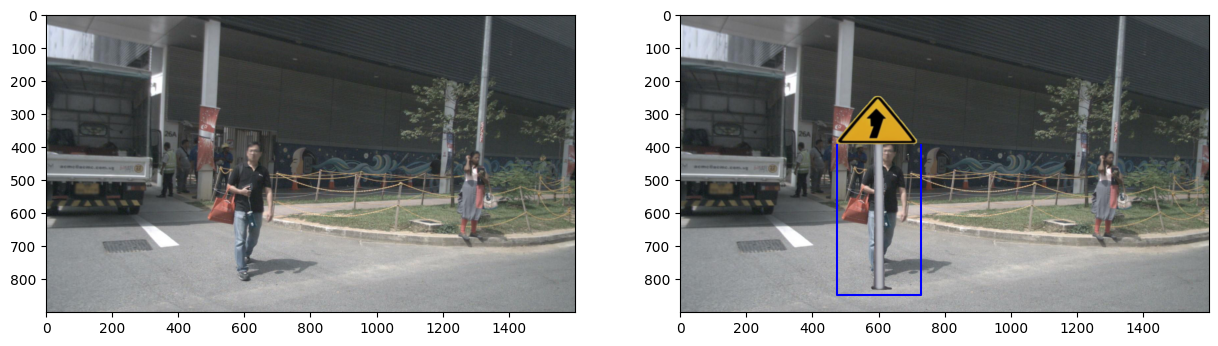

In [15]:
import pandas as pd
import numpy as np
from PIL import Image
from matplotlib import pyplot as plt
import os






df = pd.read_csv('Pedestrians_annotations_filtered_FOV_with_rain_3D_bbox_eulerian_angels.csv', sep=",")
df['2D_bbox_x1'] = df['2D_bbox_x1'].replace(',', '.', regex=True).astype(float)
df['2D_bbox_y1'] = df['2D_bbox_y1'].replace(',', '.', regex=True).astype(float)
df['2D_bbox_x2'] = df['2D_bbox_x2'].replace(',', '.', regex=True).astype(float)
df['2D_bbox_y2'] = df['2D_bbox_y2'].replace(',', '.', regex=True).astype(float)



index = 90710
index = 172897


#index = 172897 # Image 1
#index = 43512  # Image 2
#index = 146687 # Image 3
index = 90710  # Image 4
#index = 97665  # Image N





df_view = df[index:index+10]
imgs_list = df_view["img_path"]
scene_desc = df_view["scene_desc"]
obj_distance = df_view["obj_distance"]
blurriness = df_view["blurr_laplician_variance"]
avg_bright_pixel = df_view["average_brightness_pixel_lvl"]



bboxes_GT = []
bboxes_3D_GT = []
for i, row in df_view.iterrows():
    bboxes_GT.append([float(row["2D_bbox_x1"]), float(row["2D_bbox_y1"]),
                      float(row["2D_bbox_x2"]), float(row["2D_bbox_y2"])])
    bboxes_3D_GT.append([float(row["3D_bbox_x_center"]), float(row["3D_bbox_y_center"]), float(row["3D_bbox_z_center"]),
                                 float(row["3D_bbox_w"]), float(row["3D_bbox_l"]), float(row["3D_bbox_h"]), 
                                 float(row["3D_bbox_roll"]), float(row["3D_bbox_pitch"]), float(row["3D_bbox_yaw"])])


    
    
    
    
    
    
    
    
    


############## Photo-realistic augmentation of images ###################################
# Declaring the synthetic objects and their img file paths, #Image sizes, 600 length in horizontal,   and from 300 top to bottom
synthetic_objects = {"human walking": "./images/occluding-objects/human walking 2004.png",
         "car": "./images/occluding-objects/car47.png",
         "construction fence": "./images/occluding-objects/Construction fence.png",
         "concrete barrier": "./images/occluding-objects/concrete barrier.png",
         "traffic sign": "./images/occluding-objects/traffic sign - triangle 2 - Copy (4) - Copy.png",
         "bush": "./images/occluding-objects/bush.png",
         "building wall": "./images/occluding-objects/building wall.png",
         "fence": "./images/occluding-objects/fence 3.png",
         "construction barrier": "./images/occluding-objects/construction barrier.png",
         "pole": "./images/occluding-objects/pole.png",
         "trashcan": "./images/occluding-objects/trashcan.png",
         "Tree": "./images/occluding-objects/Tree.png",}

objectType = "traffic sign"
syn_obj_img_file_path = synthetic_objects[objectType]

removing_pixels = False
smoothing_on = True
image_processing_on = True
imgs, GT_bbox_aug = intervention_photorealistic_augmentations(imgs_list, bboxes_GT, bboxes_3D_GT, scene_desc, obj_distance, 
                          blurriness, avg_bright_pixel, syn_obj_img_file_path, objectType, removing_pixels, 
                          smoothing_on, image_processing_on)







############## Codif augmentations ################### ###################################
occl_colour = "colour_avg"
occl_colour = "black"
occl_colour = "blue"


occl_type = "human walking"
occl_type = "sideways_left"
occl_type = "sideways_right"
occl_type = "vertical_middle"
occl_type = "bottom"



occl_colour = "colour_avg"
occl_type = "bottom"

#occl_type = "bottom"
visibility_distribution = False
which_side_dense_prob = "uniform2"
#imgs, GT_bbox_aug = intervention_monochromatic_augmentations(imgs_list, bboxes_GT, bboxes_3D_GT, occl_colour, occl_type,
#                                      visibility_distribution, which_side_dense_prob)






##############  Plotting #################################
img = Image.open(imgs_list[index])
img.load()
data = np.asarray( img, dtype="int32" )
f, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 15))
ax1.imshow(data)
ax2.imshow(imgs[0])

# Visualize GT bbox of pedestrian
bbox_GT = np.asarray([[df_view["2D_bbox_x1"][index], df_view["2D_bbox_y1"][index]], 
                      [df_view["2D_bbox_x1"][index], df_view["2D_bbox_y2"][index]],
                      [df_view["2D_bbox_x2"][index], df_view["2D_bbox_y2"][index]],
                      [df_view["2D_bbox_x2"][index], df_view["2D_bbox_y1"][index]]])




ax2.plot(bbox_GT[:,0], bbox_GT[:,1], color="b")
plt.show()




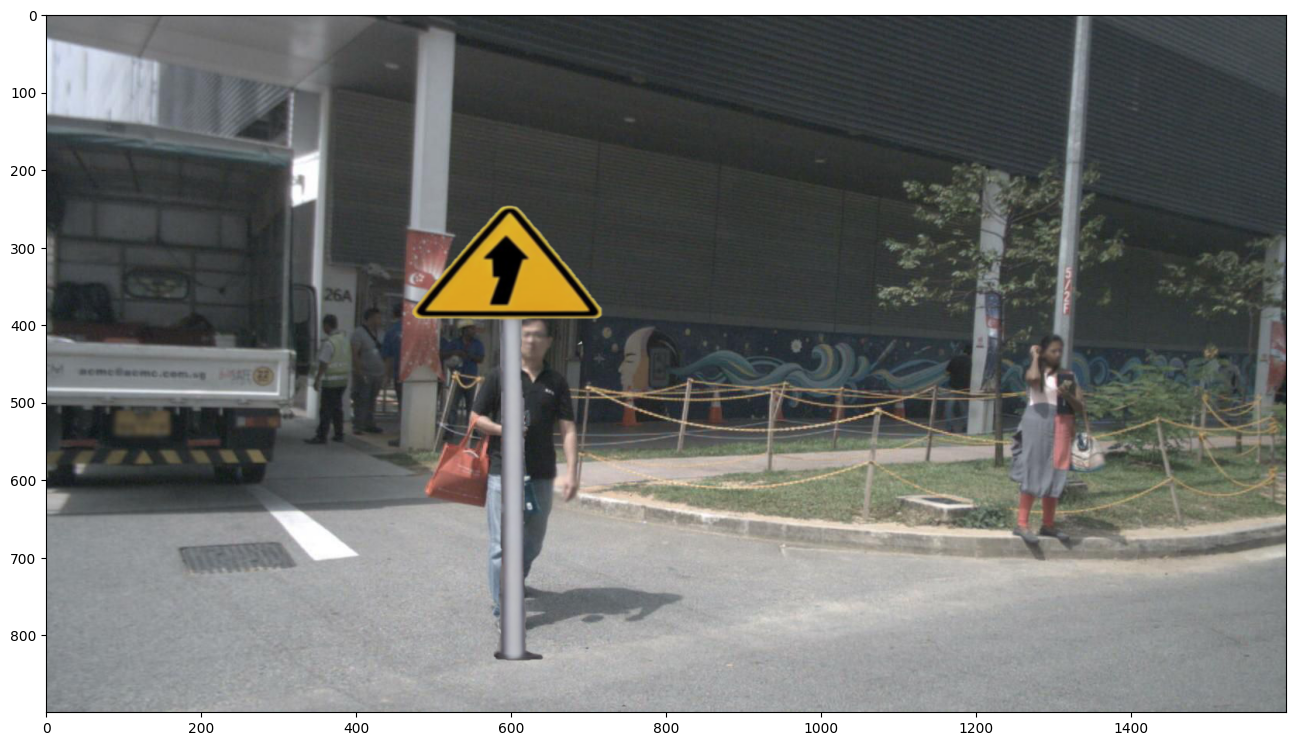

In [16]:
plt.figure(figsize = (16,16))
plt.imshow(imgs[0])
#plt.imshow(data)




## Main execution block

The following cell defines the parameters for the main execution block. The upcoming cells contain the main loops that execute the predicitions



In [ ]:
from mmdet.apis import DetInferencer
import torch
import os
import pickle
import pandas as pd
import pandas as pd




clf_treshold = 0.10
iou_treshold = 0.50
batch_size = 100
cam_type = "nuScenes"
removing_pixels = False
smoothing_on = True
image_processing_on = True
intervening_mode = True



################ Synthetic augmentations ########################
param_real_synthetic = (("human walking", "./images/occluding-objects/human walking 2004.png"),
         ("car", "./images/occluding-objects/car47.png"),
         ("construction fence", "./images/occluding-objects/Construction fence.png"),
         ("concrete barrier", "./images/occluding-objects/concrete barrier.png"),
         ("traffic sign", "./images/occluding-objects/traffic sign - triangle 2 - Copy (4) - Copy.png"),
         ("bush", "./images/occluding-objects/bush.png"),
         ("building wall", "./images/occluding-objects/building wall.png"),
         ("fence", "./images/occluding-objects/fence.png"),
         ("construction barrier", "./images/occluding-objects/construction barrier.png"),
         ("pole", "./images/occluding-objects/pole.png"),
         ("trashcan", "./images/occluding-objects/trashcan.png"),
         ("Tree", "./images/occluding-objects/Tree.png"),)
objectType = "car"             
filepath = "car47.png"




################ CODIF params ########################
param_codif = (("human walking", "black"),
         ("sideways_left", "black"),
         ("vertical_middle", "black"),
         ("bottom", "black"),
         ("human walking", "colour_avg"),
         ("sideways_left", "colour_avg"),
         ("vertical_middle", "colour_avg"),
         ("bottom", "colour_avg"))
occl_colour = "black"
occl_type = "bottom"
occl_type = "sideways_right"
occl_type = "sideways_left"
occl_type = "vertical_middle"
visibility_distribution = False
which_side_dense_prob = "false"

    


    


## Main execution loops for FCOS 

In [ ]:
df = pd.read_csv('10k_Fully_Visible_pedestrians.csv', sep=",")
infos = pickle.load( open( "infos_10k_random_fully_visible3.pkl", "rb" ))
ml_model_name = "FCOS"
ml_model = FCOS3DInferencer(model = 'fcos3d_r101-caffe-dcn_fpn_head-gn_8xb2-1x_nus-mono3d_finetune',
                            weights='fcos3d_r101_caffe_fpn_gn-head_dcn_2x8_1x_nus-mono3d_finetune_20210717_095645-8d806dc2.pth', device='cuda:0')
                            #show_progress= False)
################ Main execeution loop - photorealistic objects################
CODIF_run = False  # Choose wether to run CODIF augmentations or real synthetic augmentsions
for objectType,filepath in param_real_synthetic:   # Choose to loop through CODIF augmentations or real synthetic augmentsions
    print(objectType)
    print(filepath)
    df_result = main_loop_prev(df, clf_treshold, iou_treshold, ml_model, intervening_mode, CODIF_run, occl_colour, occl_type, visibility_distribution, which_side_dense_prob,
                               batch_size, filepath, objectType,removing_pixels, smoothing_on, image_processing_on, cam_type, infos)
    df_result.to_csv(ml_model_name + "-intervention-augmentation-" + objectType  + ".csv")
    #df_result.to_csv(ml_model_name + "-10000-intervention-augmentation-" + occl_type + "-" +occl_colour  + ".csv")
    #df_result.to_csv("FCOS_10k_sample_half_occluded_construction_barrier.csv")
    


################ Main execeution loop - CODIF ################
CODIF_run = True  # Choose wether to run CODIF augmentations or real synthetic augmentsions
for occl_type,occl_colour in param_codif:   # Choose to loop through CODIF augmentations or real synthetic augmentsions
    print(occl_type)
    print(occl_colour)
    df_result = main_loop_prev(df, clf_treshold, iou_treshold, ml_model, intervening_mode, CODIF_run, occl_colour, occl_type, visibility_distribution, which_side_dense_prob,
                               batch_size, filepath, objectType,removing_pixels, smoothing_on, image_processing_on, cam_type, infos)
    df_result.to_csv(ml_model_name + "intervention-augmentation-" + occl_type  + "-" + occl_colour + ".csv")
    #df_result.to_csv(ml_model_name + "-10000-intervention-augmentation-" + occl_type + "-" +occl_colour  + ".csv")
    #df_result.to_csv("FCOS_10k_sample_half_occluded_construction_barrier.csv")

## Main execution loop for PGD

In [ ]:
df = pd.read_csv('10k_Fully_Visible_pedestrians.csv', sep=",")
infos = pickle.load( open( "infos_10k_Fully_Visible_pedestrians.pkl", "rb" ))
ml_model_name = "PGD"
ml_model = FCOS3DInferencer(model = 'pgd_r101-caffe_fpn_head-gn_16xb2-2x_nus-mono3d_finetune',
                            weights='pgd_r101_caffe_fpn_gn-head_2x16_2x_nus-mono3d_finetune_20211114_162135-5ec7c1cd.pth',  device='cuda:0')


################ Main execeution loop - photorealistic objects ################
CODIF_run = False  # Choose wether to run CODIF augmentations or real synthetic augmentsions
for objectType,filepath in param_real_synthetic:   # Choose to loop through CODIF augmentations or real synthetic augmentsions
    print(objectType)
    print(filepath)
    df_result = main_loop_prev(df, clf_treshold, iou_treshold, ml_model, intervening_mode, CODIF_run, occl_colour, occl_type, visibility_distribution, which_side_dense_prob,
                               batch_size, filepath, objectType,removing_pixels, smoothing_on, image_processing_on, cam_type, infos)
    df_result.to_csv(ml_model_name + "intervention-augmentation-" + objectType  + ".csv")
    #df_result.to_csv(ml_model_name + "-10000-intervention-augmentation-" + occl_type + "-" +occl_colour  + ".csv")
    #df_result.to_csv("FCOS_10k_sample_half_occluded_construction_barrier.csv")
    
    




################ Main execeution loop - CODIF ################    
CODIF_run = True  # Choose wether to run CODIF augmentations or real synthetic augmentsions
for occl_type,occl_colour in param_codif:   # Choose to loop through CODIF augmentations or real synthetic augmentsions
    print(occl_type)
    print(occl_colour)
    df_result = main_loop_prev(df, clf_treshold, iou_treshold, ml_model, intervening_mode, CODIF_run, occl_colour, occl_type, visibility_distribution, which_side_dense_prob,
                               batch_size, filepath, objectType,removing_pixels, smoothing_on, image_processing_on, cam_type, infos)
    df_result.to_csv(ml_model_name + "intervention-augmentation-" + occl_type + "-" + occl_colour + ".csv")
    #df_result.to_csv(ml_model_name + "-10000-intervention-augmentation-" + occl_type + "-" +occl_colour  + ".csv")
    #df_result.to_csv("FCOS_10k_sample_half_occluded_construction_barrier.csv")

## Main execution loop for associational evaluation without augmentations

Each of the cells represent a specific ML model (FCOS or PGD) with occlusion specific (either fully visible or half occluded) dataset

In [ ]:
df = pd.read_csv('FULL-data_fully_visible_pedestrians.csv', sep=",")
infos = pickle.load( open( "infos_FULL_fully_visible_pedestrians.pkl", "rb" ))

ml_model_name = "FCOS"
ml_model = FCOS3DInferencer(model = 'fcos3d_r101-caffe-dcn_fpn_head-gn_8xb2-1x_nus-mono3d_finetune',
                            weights='fcos3d_r101_caffe_fpn_gn-head_dcn_2x8_1x_nus-mono3d_finetune_20210717_095645-8d806dc2.pth', device='cuda:0')
                            #show_progress= False)
intervening_mode = False
################ Main execeution loop ################
CODIF_run = False  # Choose wether to run CODIF augmentations or real synthetic augmentsions
df_result = main_loop_prev(df, clf_treshold, iou_treshold, ml_model, intervening_mode, CODIF_run, occl_colour, occl_type, visibility_distribution, which_side_dense_prob,
                           batch_size, filepath, objectType,removing_pixels, smoothing_on, image_processing_on, cam_type, infos)
df_result.to_csv(ml_model_name + "-fully-visible-no-augmentation.csv")
    #df_result.to_csv(ml_model_name + "-10000-intervention-augmentation-" + occl_type + "-" +occl_colour  + ".csv")
    #df_result.to_csv("FCOS_10k_sample_half_occluded_construction_barrier.csv")


In [ ]:
df = pd.read_csv('FULL-data_fully_visible_pedestrians.csv', sep=",")
infos = pickle.load( open( "infos_FULL_fully_visible_pedestrians.pkl", "rb" ))

ml_model_name = "PGD"
ml_model = FCOS3DInferencer(model = 'pgd_r101-caffe_fpn_head-gn_16xb2-2x_nus-mono3d_finetune',
                            weights='pgd_r101_caffe_fpn_gn-head_2x16_2x_nus-mono3d_finetune_20211114_162135-5ec7c1cd.pth',  device='cuda:0')

intervening_mode = False
################ Main execeution loop ################
CODIF_run = False  # Choose wether to run CODIF augmentations or real synthetic augmentsions
df_result = main_loop_prev(df, clf_treshold, iou_treshold, ml_model, intervening_mode, CODIF_run, occl_colour, occl_type, visibility_distribution, which_side_dense_prob,
                           batch_size, filepath, objectType,removing_pixels, smoothing_on, image_processing_on, cam_type, infos)
df_result.to_csv(ml_model_name + "-fully-visible-no-augmentation.csv")
    #df_result.to_csv(ml_model_name + "-10000-intervention-augmentation-" + occl_type + "-" +occl_colour  + ".csv")
    #df_result.to_csv("FCOS_10k_sample_half_occluded_construction_barrier.csv")



In [ ]:
df = pd.read_csv('FULL_half_occluded_pedestrians.csv', sep=",")
infos = pickle.load( open( "infos_FULL_half_occluded.pkl", "rb" ))

ml_model_name = "FCOS"
ml_model = FCOS3DInferencer(model = 'fcos3d_r101-caffe-dcn_fpn_head-gn_8xb2-1x_nus-mono3d_finetune',
                            weights='fcos3d_r101_caffe_fpn_gn-head_dcn_2x8_1x_nus-mono3d_finetune_20210717_095645-8d806dc2.pth', device='cuda:0')
                            #show_progress= False)
intervening_mode = False
################ Main execeution loop ################
CODIF_run = False  # Choose wether to run CODIF augmentations or real synthetic augmentsions
df_result = main_loop_prev(df, clf_treshold, iou_treshold, ml_model, intervening_mode, CODIF_run, occl_colour, occl_type, visibility_distribution, which_side_dense_prob,
                           batch_size, filepath, objectType,removing_pixels, smoothing_on, image_processing_on, cam_type, infos)
df_result.to_csv(ml_model_name + "-half-occluded-no-augmentation.csv")
    #df_result.to_csv(ml_model_name + "-10000-intervention-augmentation-" + occl_type + "-" +occl_colour  + ".csv")
    #df_result.to_csv("FCOS_10k_sample_half_occluded_construction_barrier.csv")



In [ ]:
df = pd.read_csv('FULL_half_occluded_pedestrians.csv', sep=",")
infos = pickle.load( open( "infos_FULL_half_occluded.pkl", "rb" ))

ml_model_name = "PGD"
ml_model = FCOS3DInferencer(model = 'pgd_r101-caffe_fpn_head-gn_16xb2-2x_nus-mono3d_finetune',
                            weights='pgd_r101_caffe_fpn_gn-head_2x16_2x_nus-mono3d_finetune_20211114_162135-5ec7c1cd.pth',  device='cuda:0')

intervening_mode = False
################ Main execeution loop ################
CODIF_run = False  # Choose wether to run CODIF augmentations or real synthetic augmentsions
df_result = main_loop_prev(df, clf_treshold, iou_treshold, ml_model, intervening_mode, CODIF_run, occl_colour, occl_type, visibility_distribution, which_side_dense_prob,
                           batch_size, filepath, objectType,removing_pixels, smoothing_on, image_processing_on, cam_type, infos)
df_result.to_csv(ml_model_name + "-half-occluded-no-augmentation.csv")
    #df_result.to_csv(ml_model_name + "-10000-intervention-augmentation-" + occl_type + "-" +occl_colour  + ".csv")
    #df_result.to_csv("FCOS_10k_sample_half_occluded_construction_barrier.csv")

